# Assignment 9: K-Medoids Clustering, PAM, CLARA and CLARANS

**Soumik Bhattacharyya**  
**MDE2026005**

In [2]:
import time
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score

np.random.seed(42)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

## Part A: Dataset and Distance Preparation

### Task 1: Inspect the Dataset

In [3]:
data = load_iris()

X_original = data.data
y = data.target
feature_names = data.feature_names
class_names = data.target_names

print("Number of records:", X_original.shape[0])
print("Number of numerical features:", X_original.shape[1])
print("\nFeature names:")
print(feature_names)
print("\nClass names:")
print(class_names)
print("\nClass counts:")
print(pd.Series(y).map(dict(enumerate(class_names))).value_counts())

iris_df = pd.DataFrame(X_original, columns=feature_names)
iris_df["species"] = pd.Series(y).map(dict(enumerate(class_names)))

display(iris_df.head(10))
display(iris_df[feature_names].describe())

print("Missing values:", iris_df[feature_names].isna().sum().sum())
print("Infinite values:", np.isinf(X_original).sum())

Number of records: 150
Number of numerical features: 4

Feature names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Class names:
['setosa' 'versicolor' 'virginica']

Class counts:
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
5,5.4,3.9,1.7,0.4,setosa
6,4.6,3.4,1.4,0.3,setosa
7,5.0,3.4,1.5,0.2,setosa
8,4.4,2.9,1.4,0.2,setosa
9,4.9,3.1,1.5,0.1,setosa


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


Missing values: 0
Infinite values: 0


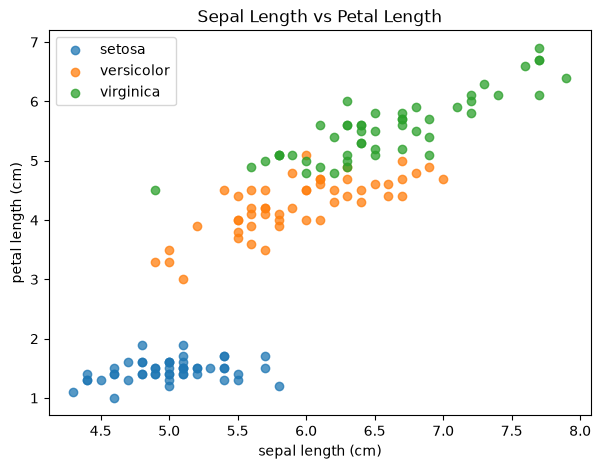

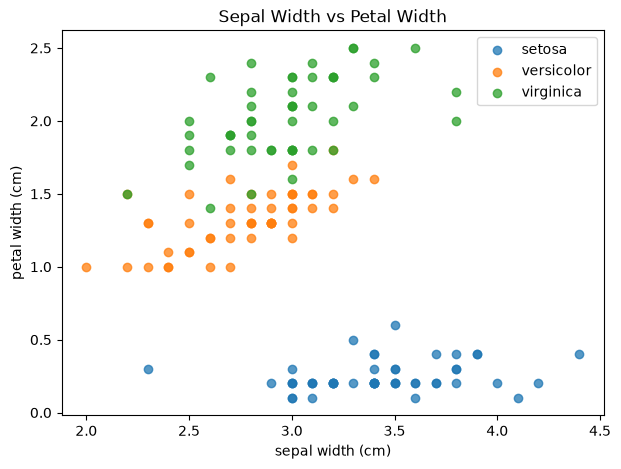

In [4]:
plt.figure(figsize=(7, 5))
for species_id, species_name in enumerate(class_names):
    mask = y == species_id
    plt.scatter(X_original[mask, 0], X_original[mask, 2], label=species_name, alpha=0.75)
plt.xlabel(feature_names[0])
plt.ylabel(feature_names[2])
plt.title("Sepal Length vs Petal Length")
plt.legend()
plt.show()

plt.figure(figsize=(7, 5))
for species_id, species_name in enumerate(class_names):
    mask = y == species_id
    plt.scatter(X_original[mask, 1], X_original[mask, 3], label=species_name, alpha=0.75)
plt.xlabel(feature_names[1])
plt.ylabel(feature_names[3])
plt.title("Sepal Width vs Petal Width")
plt.legend()
plt.show()

Iris is useful because it is small, has four numerical features, and provides labels for post-clustering evaluation.  
Its limitation is that some species overlap in feature space, so the natural groups are not perfectly separable.

### Task 2: Distance Calculation

In [9]:
def euclidean_distance(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    return np.sqrt(np.sum((x - y) ** 2))


def manhattan_distance(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    return np.sum(np.abs(x - y))


distance_pairs = [(0, 1), (0, 50), (100, 149)]
distance_rows = []

for i, j in distance_pairs:
    distance_rows.append({
        "Observation 1": i,
        "Observation 2": j,
        "Euclidean Distance": euclidean_distance(X_original[i], X_original[j]),
        "Manhattan Distance": manhattan_distance(X_original[i], X_original[j])
    })

display(pd.DataFrame(distance_rows))

,Observation 1,Observation 2,Euclidean Distance,Manhattan Distance
0,0,1,0.538516,0.7
1,0,50,4.003748,6.7
2,100,149,1.244990,2.3


Feature scaling matters because distance calculations are affected by feature magnitudes. Standardization prevents features with larger numerical ranges from dominating the distance. Euclidean distance is used for the main experiments.

### Task 3: Distance Matrix

In [8]:
X = StandardScaler().fit_transform(X_original)

subset = X[:10]
distance_matrix = np.zeros((len(subset), len(subset)))

for i in range(len(subset)):
    for j in range(len(subset)):
        distance_matrix[i, j] = euclidean_distance(subset[i], subset[j])

display(pd.DataFrame(
    distance_matrix,
    index=[f"Obs {i}" for i in range(10)],
    columns=[f"Obs {i}" for i in range(10)]
))

print("Diagonal entries are zero:", np.allclose(np.diag(distance_matrix), 0))
print("Matrix is symmetric:", np.allclose(distance_matrix, distance_matrix.T))

,Obs 0,Obs 1,Obs 2,Obs 3,Obs 4,Obs 5,Obs 6,Obs 7,Obs 8,Obs 9
Obs 0,0.000000,1.176219,0.845607,1.103685,0.260139,1.038444,0.661331,0.266276,1.620821,0.962877
Obs 1,1.176219,0.000000,0.523373,0.434000,1.386485,2.181206,0.998654,0.930463,0.648099,0.271197
Obs 2,0.845607,0.523373,0.000000,0.283891,0.991572,1.853897,0.497194,0.597511,0.782483,0.376784
Obs 3,1.103685,0.434000,0.283891,0.000000,1.250160,2.100774,0.705317,0.843695,0.523373,0.386603
Obs 4,0.260139,1.386485,0.991572,1.250160,0.000000,0.900113,0.681319,0.463889,1.767789,1.166192
Obs 5,1.038444,2.181206,1.853897,2.100774,0.900113,0.000000,1.520129,1.281367,2.620230,1.981742
Obs 6,0.661331,0.998654,0.497194,0.705317,0.681319,1.520129,0.000000,0.505434,1.183561,0.825584
Obs 7,0.266276,0.930463,0.597511,0.843695,0.463889,1.281367,0.505434,0.000000,1.362547,0.713389
Obs 8,1.620821,0.648099,0.782483,0.523373,1.767789,2.620230,1.183561,1.362547,0.000000,0.774313
Obs 9,0.962877,0.271197,0.376784,0.386603,1.166192,1.981742,0.825584,0.713389,0.774313,0.000000


Diagonal entries are zero: True
Matrix is symmetric: True


An \(N \times N\) distance matrix requires \(O(N^2)\) storage, which becomes expensive for large datasets.  
The implementations below calculate distances on demand rather than storing the full matrix.

### Task 4: K-Medoids Objective

In [10]:
def assign_to_nearest_medoid(X, medoids):
    medoids = np.asarray(medoids, dtype=int)
    distances = np.array([
        [euclidean_distance(point, X[medoid]) for medoid in medoids]
        for point in X
    ])
    assignments = np.argmin(distances, axis=1)
    nearest_distances = distances[np.arange(len(X)), assignments]
    return assignments, nearest_distances


def total_cost(X, medoids):
    _, nearest_distances = assign_to_nearest_medoid(X, medoids)
    return float(np.sum(nearest_distances))


small_example = np.array([
    [0.0, 0.0],
    [0.0, 1.0],
    [1.0, 0.0],
    [8.0, 8.0],
    [9.0, 8.0]
])
small_medoids = [0, 3]
small_assignments, small_distances = assign_to_nearest_medoid(small_example, small_medoids)

display(pd.DataFrame({
    "Point": range(len(small_example)),
    "Coordinates": list(small_example),
    "Assigned Medoid Index": [small_medoids[a] for a in small_assignments],
    "Distance to Medoid": small_distances
}))
print("Total cost:", total_cost(small_example, small_medoids))

,Point,Coordinates,Assigned Medoid Index,Distance to Medoid
0,0,"[0.0, 0.0]",0,0.0
1,1,"[0.0, 1.0]",0,1.0
2,2,"[1.0, 0.0]",0,1.0
3,3,"[8.0, 8.0]",3,0.0
4,4,"[9.0, 8.0]",3,1.0


Total cost: 3.0


A medoid is an actual observation whose total distance to assigned observations is minimized. A centroid is the arithmetic mean of a cluster and may not correspond to any real observation. We use \(k=3\) because Iris has three known species; species labels remain excluded from clustering and are used only for evaluation.

## Part B: K-Medoids using PAM

### Task 5: Initialize Medoids

In [11]:
def initialize_medoids(X, k, random_state=42):
    rng = np.random.default_rng(random_state)
    return rng.choice(len(X), size=k, replace=False)


for seed in [10, 42, 100]:
    initial_medoids = initialize_medoids(X, 3, random_state=seed)
    print(f"Seed {seed}")
    print("Medoid indices:", initial_medoids)
    print("Medoid feature values:\n", X[initial_medoids])
    print("Initial objective cost:", total_cost(X, initial_medoids))
    print()

Seed 10
Medoid indices: [ 39 142 114]
Medoid feature values:
 [[-0.90068117  0.78880759 -1.2833891  -1.3154443 ]
 [-0.05250608 -0.82256978  0.76275827  0.92230284]
 [-0.05250608 -0.59237301  0.76275827  1.58046376]]
Initial objective cost: 175.50685701532143

Seed 42
Medoid indices: [ 98  13 115]
Medoid feature values:
 [[-0.90068117 -1.28296331 -0.4308277  -0.13075464]
 [-1.87002413 -0.13197948 -1.51073881 -1.44707648]
 [ 0.67450115  0.32841405  0.87643312  1.44883158]]
Initial objective cost: 191.94619258614864

Seed 100
Medoid indices: [ 18 113 124]
Medoid feature values:
 [[-0.17367395  1.70959465 -1.16971425 -1.18381211]
 [-0.17367395 -1.28296331  0.70592084  1.05393502]
 [ 1.03800476  0.55861082  1.10378283  1.18556721]]
Initial objective cost: 184.13256134959596



Different initial medoids can lead to different local solutions because PAM accepts cost-reducing swaps and stops when no improving swap remains. It is not guaranteed to find the global optimum from every initialization.

### Tasks 6–7: PAM Swap Step and Complete Algorithm

In [12]:
def pam(X, k, max_iter=100, random_state=42, initial_medoids=None, verbose=False):
    X = np.asarray(X, dtype=float)

    if initial_medoids is None:
        medoids = initialize_medoids(X, k, random_state)
    else:
        medoids = np.asarray(initial_medoids, dtype=int).copy()

    if len(np.unique(medoids)) != k:
        raise ValueError("Medoids must be distinct.")
    if np.any(medoids < 0) or np.any(medoids >= len(X)):
        raise ValueError("Medoid index out of range.")

    current_cost = total_cost(X, medoids)
    history = [current_cost]
    swap_log = []
    iterations = 0

    for iteration in range(max_iter):
        iterations = iteration + 1
        best_cost = current_cost
        best_swap = None

        non_medoids = [i for i in range(len(X)) if i not in medoids]

        for medoid_position, outgoing in enumerate(medoids):
            for incoming in non_medoids:
                candidate = medoids.copy()
                candidate[medoid_position] = incoming
                candidate_cost = total_cost(X, candidate)

                accepted = candidate_cost < current_cost - 1e-12
                swap_log.append({
                    "Iteration": iterations,
                    "Outgoing Medoid": int(outgoing),
                    "Incoming Observation": int(incoming),
                    "Old Cost": current_cost,
                    "Candidate Cost": candidate_cost,
                    "Improves Current": accepted
                })

                if candidate_cost < best_cost - 1e-12:
                    best_cost = candidate_cost
                    best_swap = candidate

        if best_swap is None:
            break

        old_cost = current_cost
        medoids = best_swap
        current_cost = best_cost
        history.append(current_cost)

        if verbose:
            print(f"Iteration {iterations}: cost {old_cost:.4f} -> {current_cost:.4f}")

    assignments, nearest_distances = assign_to_nearest_medoid(X, medoids)
    return {
        "medoids": medoids,
        "assignments": assignments,
        "distances": nearest_distances,
        "cost": current_cost,
        "iterations": iterations,
        "history": history,
        "swaps": pd.DataFrame(swap_log)
    }


pam_start = initialize_medoids(X, 3, random_state=42)
pam_initial_cost = total_cost(X, pam_start)
pam_start_time = time.perf_counter()
pam_result = pam(X, 3, max_iter=100, random_state=42, initial_medoids=pam_start, verbose=True)
pam_runtime = time.perf_counter() - pam_start_time

print("Initial medoids:", pam_start)
print("Initial cost:", pam_initial_cost)
print("Final medoids:", pam_result["medoids"])
print("Final cost:", pam_result["cost"])
print("Iterations:", pam_result["iterations"])
print("Cluster sizes:", np.bincount(pam_result["assignments"], minlength=3))
display(pam_result["swaps"].head(20))

Iteration 1: cost 191.9462 -> 158.9309
Iteration 2: cost 158.9309 -> 138.6607
Iteration 3: cost 138.6607 -> 131.7958
Initial medoids: [ 98  13 115]
Initial cost: 191.94619258614864
Final medoids: [ 55   7 112]
Final cost: 131.79582351564602
Iterations: 4
Cluster sizes: [55 50 45]


,Iteration,Outgoing Medoid,Incoming Observation,Old Cost,Candidate Cost,Improves Current
0,1,98,0,191.946193,187.418611,True
1,1,98,1,191.946193,208.980863,False
2,1,98,2,191.946193,201.322113,False
3,1,98,3,191.946193,208.250020,False
4,1,98,4,191.946193,187.983603,True
5,1,98,5,191.946193,196.025202,False
6,1,98,6,191.946193,197.977582,False
7,1,98,7,191.946193,189.852447,True
8,1,98,8,191.946193,224.354934,False
9,1,98,9,191.946193,203.803186,False


PAM evaluates medoid/non-medoid replacements and accepts the best available improving swap in each iteration. Accepted swaps reduce the objective cost; the search stops when no improving swap exists or the iteration limit is reached.

### Task 8: Examine PAM Results

In [13]:
def medoid_summary(X, medoids, assignments, distances, feature_names):
    rows = []
    for cluster_id, medoid_index in enumerate(medoids):
        cluster_distances = distances[assignments == cluster_id]
        row = {
            "Cluster": cluster_id,
            "Medoid Index": int(medoid_index),
            "Cluster Size": int(np.sum(assignments == cluster_id)),
            "Mean Distance": float(np.mean(cluster_distances)) if len(cluster_distances) else np.nan,
            "Max Distance": float(np.max(cluster_distances)) if len(cluster_distances) else np.nan
        }
        row.update({feature_names[j]: X[medoid_index, j] for j in range(X.shape[1])})
        rows.append(row)
    return pd.DataFrame(rows)


display(medoid_summary(X, pam_result["medoids"], pam_result["assignments"],
                       pam_result["distances"], feature_names))
print("Total objective cost:", pam_result["cost"])
print("Average distance to assigned medoid:", np.mean(pam_result["distances"]))
print("ARI:", adjusted_rand_score(y, pam_result["assignments"]))
print("NMI:", normalized_mutual_info_score(y, pam_result["assignments"]))

,Cluster,Medoid Index,Cluster Size,Mean Distance,Max Distance,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,0,55,55,0.897532,2.142379,-0.173674,-0.592373,0.421734,0.132510
1,1,7,50,0.816460,2.609434,-1.021849,0.788808,-1.283389,-1.315444
2,2,112,45,0.924635,2.333854,1.159173,-0.131979,0.990108,1.185567


Total objective cost: 131.79582351564602
Average distance to assigned medoid: 0.8786388234376401
ARI: 0.6416026620488269
NMI: 0.6750498631643848


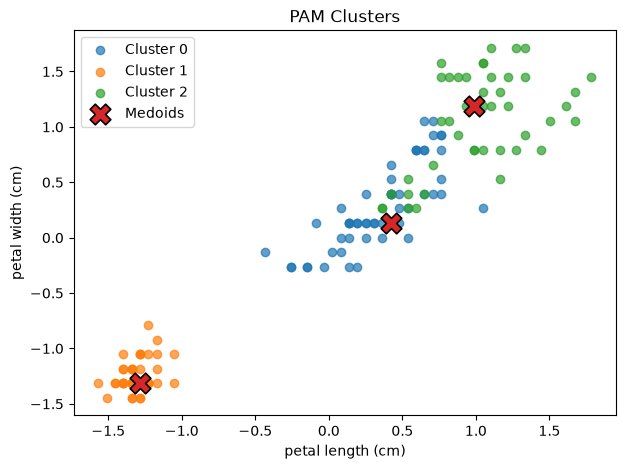

In [14]:
def plot_clusters(X, result, title, feature_x=2, feature_y=3, feature_names=feature_names):
    assignments = result["assignments"]
    medoids = result["medoids"]

    plt.figure(figsize=(7, 5))
    for cluster_id in sorted(np.unique(assignments)):
        mask = assignments == cluster_id
        plt.scatter(X[mask, feature_x], X[mask, feature_y],
                    label=f"Cluster {cluster_id}", alpha=0.7)
    plt.scatter(X[medoids, feature_x], X[medoids, feature_y],
                marker="X", s=220, edgecolor="black", linewidth=1.2,
                label="Medoids")
    plt.xlabel(feature_names[feature_x])
    plt.ylabel(feature_names[feature_y])
    plt.title(title)
    plt.legend()
    plt.show()


plot_clusters(X, pam_result, "PAM Clusters", feature_x=2, feature_y=3)

1. PAM forms three reasonably balanced clusters of sizes 55, 50, and 45, with an average distance to the assigned medoid of 0.879. Its ARI of 0.642 and NMI of 0.675 indicate moderate agreement with the actual Iris species.

2. Some overlap between species limits perfect separation. Since clustering uses feature distances rather than species labels, the resulting clusters need not correspond exactly to the three species. The medoid-based approach is robust to extreme values compared with centroid-based clustering, but it can still be affected by outliers and initialization.

## Part C: CLARA — Clustering Large Applications

### Task 9: Sampling

In [16]:
def draw_sample(X, sample_size, random_state=42):
    if sample_size < 1 or sample_size > len(X):
        raise ValueError("sample_size must be between 1 and the number of observations.")
    rng = np.random.default_rng(random_state)
    return rng.choice(len(X), size=sample_size, replace=False)


CLARA_SAMPLE_SIZE = 40
CLARA_NUM_SAMPLES = 5
clara_sample_indices = draw_sample(X, CLARA_SAMPLE_SIZE, random_state=42)

print("Sample size:", len(clara_sample_indices))
print("Sample indices:", clara_sample_indices)
print("\nFull-data feature means:")
display(pd.DataFrame({"Full data": X.mean(axis=0)}, index=feature_names))
print("Sample feature means:")
display(pd.DataFrame({"Sample": X[clara_sample_indices].mean(axis=0)}, index=feature_names))

Sample size: 40
Sample indices: [113  11 128  23 145 124 119  13 140  82  75   9  58  87  49  16  32 149
 130 108  89  65  50 126  86 122  90  63  99  24 105  48  41 125  79  73
  94  55  62  10]

Full-data feature means:


,Full data
sepal length (cm),-1.690315e-15
sepal width (cm),-1.842970e-15
petal length (cm),-1.698641e-15
petal width (cm),-1.409243e-15


Sample feature means:


,Sample
sepal length (cm),0.165596
sepal width (cm),-0.224058
petal length (cm),0.119074
petal width (cm),0.020622


Sampling reduces the cost of searching medoid swaps because PAM runs on a smaller subset. However, a sample can omit useful representative observations, so the resulting medoids may not be the best for the full dataset.

### Task 10: Implement CLARA

In [22]:
def clara(X, k, sample_size=40, num_samples=5, random_state=42, pam_max_iter=100):
    X = np.asarray(X, dtype=float)
    if sample_size < k:
        raise ValueError("sample_size must be at least k.")
    if sample_size > len(X):
        raise ValueError("sample_size cannot exceed the dataset size.")

    rng = np.random.default_rng(random_state)
    sample_rows = []
    best_result = None
    best_cost = np.inf

    for sample_number in range(num_samples):
        sample_indices = rng.choice(len(X), size=sample_size, replace=False)
        sample_X = X[sample_indices]

        sample_result = pam(
            sample_X, k, max_iter=pam_max_iter,
            random_state=int(rng.integers(0, 2**32 - 1))
        )
        full_medoids = sample_indices[sample_result["medoids"]]
        full_assignments, full_distances = assign_to_nearest_medoid(X, full_medoids)
        full_cost = float(np.sum(full_distances))

        sample_rows.append({
            "Sample": sample_number + 1,
            "Sample Indices": sample_indices.copy(),
            "Medoids": full_medoids.copy(),
            "Full-data Cost": full_cost
        })

        if full_cost < best_cost:
            best_cost = full_cost
            best_result = {
                "medoids": full_medoids,
                "assignments": full_assignments,
                "distances": full_distances,
                "cost": full_cost,
                "best_sample": sample_number + 1
            }

    best_result["sample_results"] = pd.DataFrame(sample_rows)
    best_result["sample_size"] = sample_size
    best_result["num_samples"] = num_samples
    return best_result


clara_start_time = time.perf_counter()
clara_result = clara(X, 3, sample_size=CLARA_SAMPLE_SIZE,
                     num_samples=CLARA_NUM_SAMPLES, random_state=42)
clara_runtime = time.perf_counter() - clara_start_time


display(clara_result["sample_results"][["Sample", "Medoids", "Full-data Cost"]])
print("Best sample:", clara_result["best_sample"])
print("Final medoids:", clara_result["medoids"])
print("Best full-data cost:", clara_result["cost"])
print("Cluster sizes:", np.bincount(clara_result["assignments"], minlength=3))

,Sample,Medoids,Full-data Cost
0,1,"[94, 86, 11]",141.911114
1,2,"[94, 0, 139]",133.264065
2,3,"[94, 139, 17]",133.284923
3,4,"[39, 138, 93]",150.350330
4,5,"[112, 35, 83]",141.988561


Best sample: 2
Final medoids: [ 94   0 139]
Best full-data cost: 133.26406533218326
Cluster sizes: [52 49 49]


### Task 11: Analyze CLARA

CLARA evaluates every sample's candidate medoids against the full dataset and keeps the set with the lowest full-data cost. Its search is more scalable than running exhaustive PAM swaps over all observations, but its result depends on which observations appear in the samples.

## Part D: CLARANS — Randomized Local Search

### Task 12: Define a CLARANS Neighbour

In [18]:
def clarans_neighbour(X, medoids, rng):
    medoids = np.asarray(medoids, dtype=int)
    non_medoids = np.setdiff1d(np.arange(len(X)), medoids)
    if len(non_medoids) == 0:
        raise ValueError("No non-medoid observations are available.")

    medoid_position = int(rng.integers(len(medoids)))
    incoming = int(rng.choice(non_medoids))
    candidate = medoids.copy()
    outgoing = int(candidate[medoid_position])
    candidate[medoid_position] = incoming
    return candidate, outgoing, incoming


rng = np.random.default_rng(42)
neighbour_medoids = initialize_medoids(X, 3, random_state=42)
neighbour_cost = total_cost(X, neighbour_medoids)
neighbour_rows = []

for proposal in range(1, 6):
    candidate, outgoing, incoming = clarans_neighbour(X, neighbour_medoids, rng)
    candidate_cost = total_cost(X, candidate)
    neighbour_rows.append({
        "Proposal": proposal,
        "Outgoing Medoid": outgoing,
        "Incoming Observation": incoming,
        "Current Cost": neighbour_cost,
        "Candidate Cost": candidate_cost,
        "Cost Difference": candidate_cost - neighbour_cost,
        "Improves Cost": candidate_cost < neighbour_cost
    })

display(pd.DataFrame(neighbour_rows))

,Proposal,Outgoing Medoid,Incoming Observation,Current Cost,Candidate Cost,Cost Difference,Improves Cost
0,1,98,116,191.946193,193.323392,1.377199,False
1,2,13,65,191.946193,232.221665,40.275472,False
2,3,13,129,191.946193,239.382257,47.436064,False
3,4,98,104,191.946193,212.493507,20.547315,False
4,5,98,14,191.946193,203.559096,11.612904,False


Random neighbour proposals inspect only a subset of possible swaps, reducing search effort. Testing every possible medoid/non-medoid swap is more exhaustive but can be much more expensive.

### Task 13: Implement CLARANS

In [23]:
def clarans(X, k, num_local=5, max_neighbors=20, random_state=42,
            initial_medoids=None, verbose=False):
    X = np.asarray(X, dtype=float)
    rng = np.random.default_rng(random_state)

    if initial_medoids is None:
        initial_medoids = initialize_medoids(X, k, random_state)
    initial_medoids = np.asarray(initial_medoids, dtype=int)

    best_medoids = initial_medoids.copy()
    best_cost = total_cost(X, best_medoids)
    best_history = [best_cost]
    restart_rows = []
    all_proposals = []
    total_accepted = 0

    for restart in range(num_local):
        if restart == 0:
            current_medoids = best_medoids.copy()
        else:
            current_medoids = initialize_medoids(
                X, k, random_state=int(rng.integers(0, 2**32 - 1))
            )

        current_cost = total_cost(X, current_medoids)
        unsuccessful = 0
        proposals = 0
        accepted = 0
        history = [current_cost]

        while unsuccessful < max_neighbors:
            candidate, outgoing, incoming = clarans_neighbour(X, current_medoids, rng)
            candidate_cost = total_cost(X, candidate)
            proposals += 1

            improves = candidate_cost < current_cost - 1e-12
            all_proposals.append({
                "Restart": restart + 1,
                "Proposal": proposals,
                "Outgoing Medoid": outgoing,
                "Incoming Observation": incoming,
                "Old Cost": current_cost,
                "Candidate Cost": candidate_cost,
                "Improves": improves
            })

            if improves:
                current_medoids = candidate
                current_cost = candidate_cost
                unsuccessful = 0
                accepted += 1
                total_accepted += 1
                history.append(current_cost)
            else:
                unsuccessful += 1

        restart_rows.append({
            "Restart": restart + 1,
            "Final Local Cost": current_cost,
            "Neighbour Proposals": proposals,
            "Accepted Swaps": accepted,
            "Unsuccessful Checks": unsuccessful,
            "Cost History": history
        })

        if current_cost < best_cost:
            best_cost = current_cost
            best_medoids = current_medoids.copy()
            best_history = history.copy()

        if verbose:
            print(f"Restart {restart + 1}: cost={current_cost:.4f}, "
                  f"proposals={proposals}, accepted swaps={accepted}")

    assignments, distances = assign_to_nearest_medoid(X, best_medoids)
    return {
        "medoids": best_medoids,
        "assignments": assignments,
        "distances": distances,
        "cost": best_cost,
        "history": best_history,
        "restarts": pd.DataFrame(restart_rows),
        "proposals": pd.DataFrame(all_proposals),
        "num_local": num_local,
        "max_neighbors": max_neighbors,
        "random_state": random_state,
        "accepted_swaps": total_accepted
    }


CLARANS_NUM_LOCAL = 5
CLARANS_MAX_NEIGHBORS = 20

clarans_start_time = time.perf_counter()
clarans_result = clarans(
    X, 3, num_local=CLARANS_NUM_LOCAL,
    max_neighbors=CLARANS_MAX_NEIGHBORS, random_state=42, verbose=True
)
clarans_runtime = time.perf_counter() - clarans_start_time


print("Best medoids:", clarans_result["medoids"])
print("Best cost:", clarans_result["cost"])
print("Cluster sizes:", np.bincount(clarans_result["assignments"], minlength=3))
display(clarans_result["restarts"])

Restart 1: cost=137.9774, proposals=49, accepted swaps=8
Restart 2: cost=134.0104, proposals=41, accepted swaps=6
Restart 3: cost=152.9030, proposals=23, accepted swaps=2
Restart 4: cost=139.4450, proposals=62, accepted swaps=10
Restart 5: cost=141.6283, proposals=34, accepted swaps=3
Best medoids: [ 90 147  40]
Best cost: 134.01040595287583
Cluster sizes: [42 59 49]


,Restart,Final Local Cost,Neighbour Proposals,Accepted Swaps,Unsuccessful Checks,Cost History
0,1,137.977412,49,8,20,"[191.94619258614864, 173.53970507737534, 170.2..."
1,2,134.010406,41,6,20,"[246.10885137489458, 244.12840178892856, 240.0..."
2,3,152.903042,23,2,20,"[230.8298815626511, 171.2543148795715, 152.903..."
3,4,139.445027,62,10,20,"[188.0324147463411, 183.61150115824, 174.45139..."
4,5,141.628269,34,3,20,"[169.13748660043086, 165.03277021111865, 158.9..."


In CLARANS, `num_local` is the number of local searches/restarts, and `max_neighbors` is the allowed consecutive unsuccessful neighbour checks before a local search stops. A lower-cost neighbour is accepted immediately; the best solution across restarts is returned.

### Task 14: Analyze CLARANS Search Behaviour

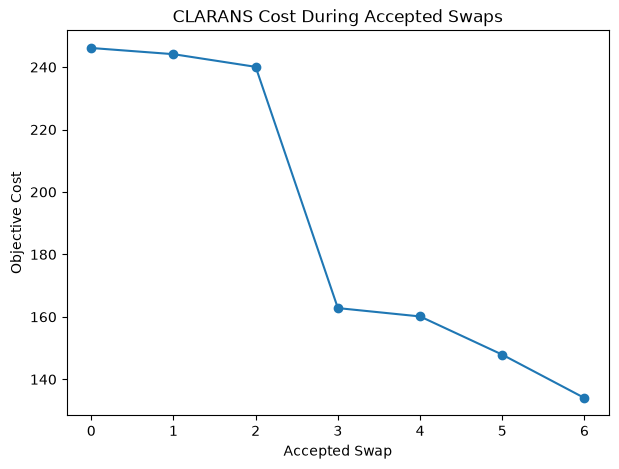

,Seed,Final Cost,Neighbour Proposals,Accepted Swaps
0,10,135.093717,207,22
1,42,134.010406,209,29
2,100,133.995100,229,27


Total neighbour proposals: 209
Accepted swaps: 29
Configured restarts: 5


In [24]:
plt.figure(figsize=(7, 5))
plt.plot(range(len(clarans_result["history"])), clarans_result["history"], marker="o")
plt.xlabel("Accepted Swap")
plt.ylabel("Objective Cost")
plt.title("CLARANS Cost During Accepted Swaps")
plt.show()

clarans_seed_rows = []
for seed in [10, 42, 100]:
    result = clarans(
        X, 3, num_local=CLARANS_NUM_LOCAL,
        max_neighbors=CLARANS_MAX_NEIGHBORS, random_state=seed
    )
    clarans_seed_rows.append({
        "Seed": seed,
        "Final Cost": result["cost"],
        "Neighbour Proposals": len(result["proposals"]),
        "Accepted Swaps": result["accepted_swaps"]
    })

display(pd.DataFrame(clarans_seed_rows))
print("Total neighbour proposals:", len(clarans_result["proposals"]))
print("Accepted swaps:", clarans_result["accepted_swaps"])
print("Configured restarts:", clarans_result["num_local"])

Randomized exploration can reduce the number of swaps evaluated compared with exhaustive search, but it can miss useful neighbours. Different random seeds explore different paths and can therefore produce different final costs.

## Part E: Evaluation and Comparison

### Task 15: Compare PAM, CLARA and CLARANS

In [25]:
results = {
    "PAM": pam_result,
    "CLARA": clara_result,
    "CLARANS": clarans_result
}

parameter_text = {
    "PAM": "k=3; max_iter=100; seed=42",
    "CLARA": f"k=3; sample_size={CLARA_SAMPLE_SIZE}; num_samples={CLARA_NUM_SAMPLES}; seed=42",
    "CLARANS": f"k=3; num_local={CLARANS_NUM_LOCAL}; max_neighbors={CLARANS_MAX_NEIGHBORS}; seed=42"
}

comparison_rows = []
for name, result in results.items():
    start_time = time.perf_counter()
    total_cost(X, result["medoids"])
    evaluation_time = time.perf_counter() - start_time
    comparison_rows.append({
        "Algorithm": name,
        "Objective Cost": result["cost"],
        "Cluster Count": len(np.unique(result["assignments"])),
        "Runtime (s)": {"PAM": pam_runtime, "CLARA": clara_runtime, "CLARANS": clarans_runtime}[name],
        "Parameters": parameter_text[name],
        "Cost Recheck Time (s)": evaluation_time
    })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)

,Algorithm,Objective Cost,Cluster Count,Runtime (s),Parameters,Cost Recheck Time (s)
0,PAM,131.795824,3,4.700070,k=3; max_iter=100; seed=42,0.003013
1,CLARA,133.264065,3,1.995390,k=3; sample_size=40; num_samples=5; seed=42,0.002697
2,CLARANS,134.010406,3,0.679143,k=3; num_local=5; max_neighbors=20; seed=42,0.002027


For a fair runtime comparison, run the algorithms on the same machine with identical data, preprocessing, distance metric, and clearly specified stopping conditions. Runtime should be measured around each complete algorithm run; the cost-recheck timing above is only a separate evaluation timing.

### Task 16: Cluster Quality Evaluation

In [26]:
evaluation_rows = []
for name, result in results.items():
    evaluation_rows.append({
        "Algorithm": name,
        "Objective Cost": result["cost"],
        "Silhouette Score": silhouette_score(X, result["assignments"], metric="euclidean"),
        "ARI": adjusted_rand_score(y, result["assignments"]),
        "NMI": normalized_mutual_info_score(y, result["assignments"])
    })

evaluation_df = pd.DataFrame(evaluation_rows)
display(evaluation_df)
print("Best silhouette:", evaluation_df.loc[evaluation_df["Silhouette Score"].idxmax(), "Algorithm"])
print("Best ARI:", evaluation_df.loc[evaluation_df["ARI"].idxmax(), "Algorithm"])
print("Best NMI:", evaluation_df.loc[evaluation_df["NMI"].idxmax(), "Algorithm"])

,Algorithm,Objective Cost,Silhouette Score,ARI,NMI
0,PAM,131.795824,0.456643,0.641603,0.675050
1,CLARA,133.264065,0.458963,0.599709,0.628928
2,CLARANS,134.010406,0.453379,0.624637,0.651238


Best silhouette: CLARA
Best ARI: PAM
Best NMI: PAM


Objective cost measures the sum of distances to medoids, while ARI/NMI measure agreement with external species labels. Lower cost does not necessarily mean better species agreement because the clustering objective does not use those labels. Silhouette can favour compact, separated clusters but may not reflect domain meaning; ARI and NMI depend on the chosen external labels and do not measure absolute cluster usefulness.

### Task 17: Effect of Number of Clusters (k)

In [27]:
k_rows = []
k_results = {}

for k_value in [2, 3, 4, 5]:
    pam_k = pam(X, k_value, max_iter=100, random_state=42)
    clara_k = clara(X, k_value, sample_size=max(40, k_value),
                    num_samples=CLARA_NUM_SAMPLES, random_state=42)
    clarans_k = clarans(X, k_value, num_local=CLARANS_NUM_LOCAL,
                        max_neighbors=CLARANS_MAX_NEIGHBORS, random_state=42)

    k_results[k_value] = {"PAM": pam_k, "CLARA": clara_k, "CLARANS": clarans_k}

    for algorithm, result in k_results[k_value].items():
        k_rows.append({
            "k": k_value,
            "Algorithm": algorithm,
            "Objective Cost": result["cost"],
            "Silhouette Score": silhouette_score(X, result["assignments"], metric="euclidean"),
            "Cluster Sizes": np.bincount(result["assignments"], minlength=k_value).tolist()
        })

k_experiment_df = pd.DataFrame(k_rows)
display(k_experiment_df)

,k,Algorithm,Objective Cost,Silhouette Score,Cluster Sizes
0,2,PAM,162.065964,0.581750,"[50, 100]"
1,2,CLARA,165.136284,0.581750,"[50, 100]"
2,2,CLARANS,164.601463,0.581750,"[100, 50]"
3,3,PAM,131.795824,0.456643,"[55, 50, 45]"
4,3,CLARA,133.264065,0.458963,"[52, 49, 49]"
5,3,CLARANS,134.010406,0.453379,"[42, 59, 49]"
6,4,PAM,116.866294,0.409112,"[37, 22, 42, 49]"
7,4,CLARA,122.092159,0.374583,"[29, 33, 49, 39]"
8,4,CLARANS,119.929641,0.391784,"[39, 35, 27, 49]"
9,5,PAM,105.028640,0.347269,"[42, 37, 21, 17, 33]"


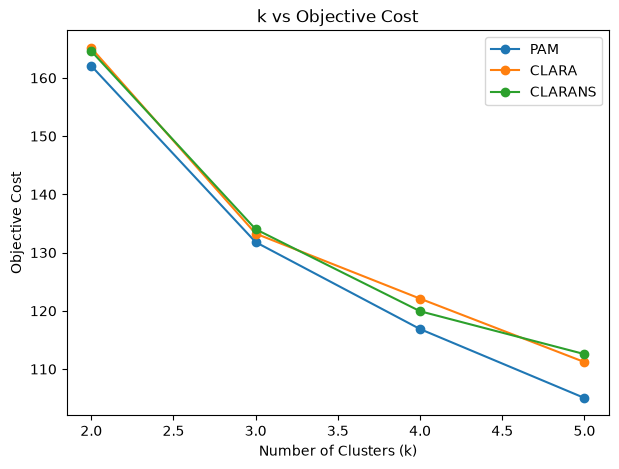

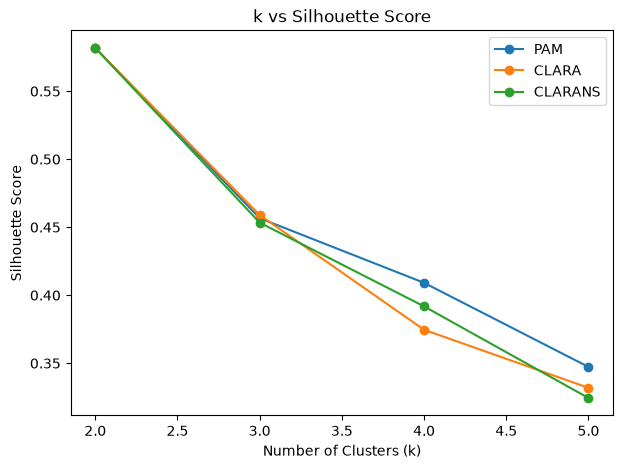

In [28]:
plt.figure(figsize=(7, 5))
for algorithm in ["PAM", "CLARA", "CLARANS"]:
    subset_df = k_experiment_df[k_experiment_df["Algorithm"] == algorithm]
    plt.plot(subset_df["k"], subset_df["Objective Cost"], marker="o", label=algorithm)
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Objective Cost")
plt.title("k vs Objective Cost")
plt.legend()
plt.show()

plt.figure(figsize=(7, 5))
for algorithm in ["PAM", "CLARA", "CLARANS"]:
    subset_df = k_experiment_df[k_experiment_df["Algorithm"] == algorithm]
    plt.plot(subset_df["k"], subset_df["Silhouette Score"], marker="o", label=algorithm)
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("k vs Silhouette Score")
plt.legend()
plt.show()

The optimal objective cost cannot increase when an additional medoid is allowed, because the previous solution remains feasible and the extra medoid can only reduce or preserve nearest-medoid distances. Silhouette may rise or fall because it balances within-cluster cohesion and separation. The preferred \(k\) depends on whether the priority is cost, separation, interpretability, or agreement with known categories.

### Task 18: Effect of CLARA Sample Size

,Sample Size,Objective Cost,Runtime (s)
0,20,140.663268,0.449013
1,40,133.264065,1.781879
2,80,132.127650,9.508087


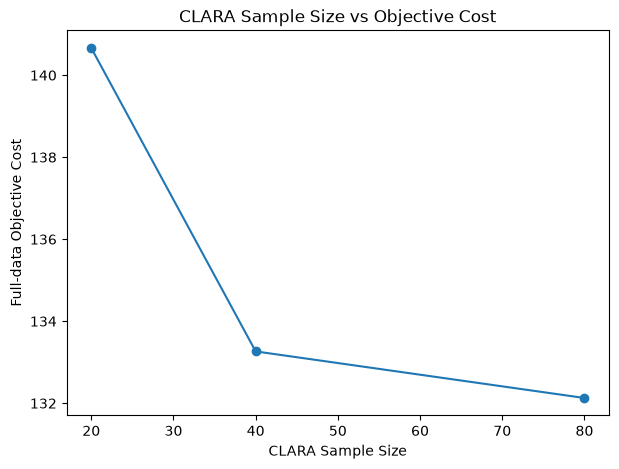

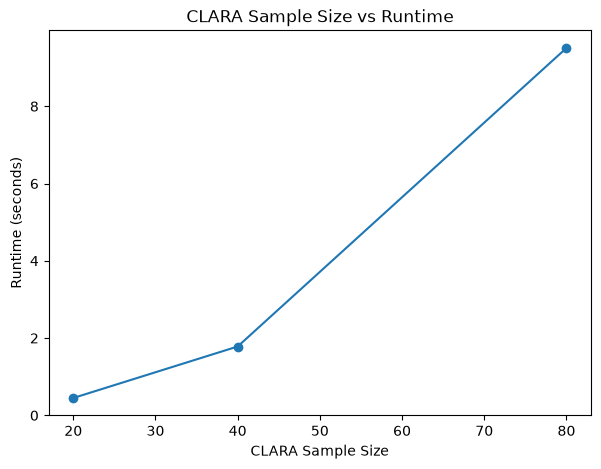

In [29]:
clara_sample_sizes = [20, 40, 80]
clara_size_rows = []

for sample_size in clara_sample_sizes:
    start = time.perf_counter()
    result = clara(X, 3, sample_size=sample_size, num_samples=5, random_state=42)
    runtime = time.perf_counter() - start
    clara_size_rows.append({
        "Sample Size": sample_size,
        "Objective Cost": result["cost"],
        "Runtime (s)": runtime
    })

clara_size_df = pd.DataFrame(clara_size_rows)
display(clara_size_df)

plt.figure(figsize=(7, 5))
plt.plot(clara_size_df["Sample Size"], clara_size_df["Objective Cost"], marker="o")
plt.xlabel("CLARA Sample Size")
plt.ylabel("Full-data Objective Cost")
plt.title("CLARA Sample Size vs Objective Cost")
plt.show()

plt.figure(figsize=(7, 5))
plt.plot(clara_size_df["Sample Size"], clara_size_df["Runtime (s)"], marker="o")
plt.xlabel("CLARA Sample Size")
plt.ylabel("Runtime (seconds)")
plt.title("CLARA Sample Size vs Runtime")
plt.show()

Larger samples increase the search work per PAM run but can include better representative observations. Smaller samples are faster, though they have a greater chance of missing useful medoids. The measured results should be used to judge this trade-off.

### Task 19: Effect of CLARANS Search Parameters

,num_local,max_neighbors,Objective Cost,Runtime (s),Neighbour Proposals,Accepted Swaps
0,3,10,137.977412,0.327561,87,17
1,5,20,134.010406,0.752798,209,29
2,8,30,133.117894,1.493864,449,44


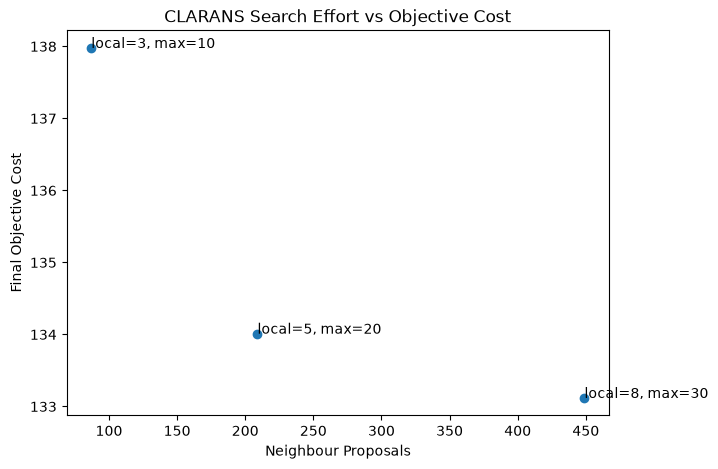

In [30]:
clarans_settings = [
    {"num_local": 3, "max_neighbors": 10},
    {"num_local": 5, "max_neighbors": 20},
    {"num_local": 8, "max_neighbors": 30}
]
clarans_parameter_rows = []

for setting in clarans_settings:
    start = time.perf_counter()
    result = clarans(
        X, 3,
        num_local=setting["num_local"],
        max_neighbors=setting["max_neighbors"],
        random_state=42
    )
    runtime = time.perf_counter() - start
    clarans_parameter_rows.append({
        "num_local": setting["num_local"],
        "max_neighbors": setting["max_neighbors"],
        "Objective Cost": result["cost"],
        "Runtime (s)": runtime,
        "Neighbour Proposals": len(result["proposals"]),
        "Accepted Swaps": result["accepted_swaps"]
    })

clarans_parameter_df = pd.DataFrame(clarans_parameter_rows)
display(clarans_parameter_df)

plt.figure(figsize=(7, 5))
plt.scatter(clarans_parameter_df["Neighbour Proposals"],
            clarans_parameter_df["Objective Cost"])
for _, row in clarans_parameter_df.iterrows():
    plt.annotate(
        f"local={int(row['num_local'])}, max={int(row['max_neighbors'])}",
        (row["Neighbour Proposals"], row["Objective Cost"])
    )
plt.xlabel("Neighbour Proposals")
plt.ylabel("Final Objective Cost")
plt.title("CLARANS Search Effort vs Objective Cost")
plt.show()

A larger search budget may explore more of the neighbourhood and find a lower-cost solution, but it requires more distance evaluations and runtime. Fixed seeds make settings reproducible; repeated seeds are still useful for measuring variation.

### Task 20: Required Visualizations

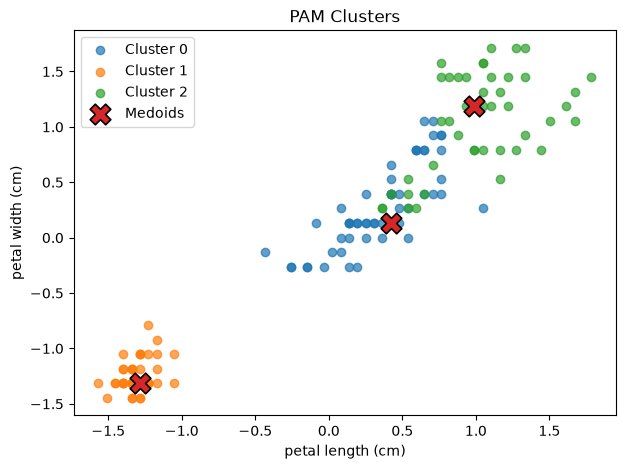

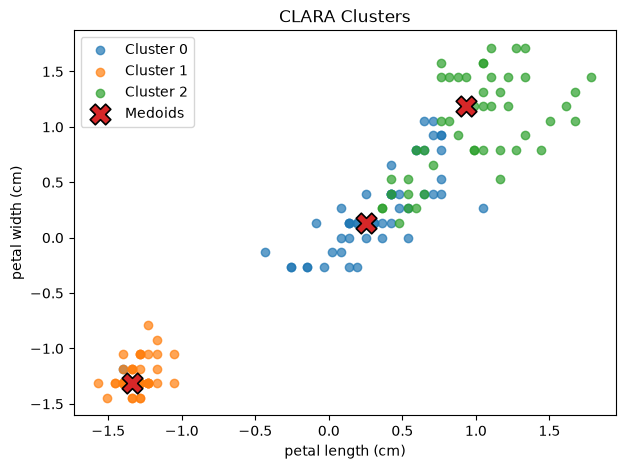

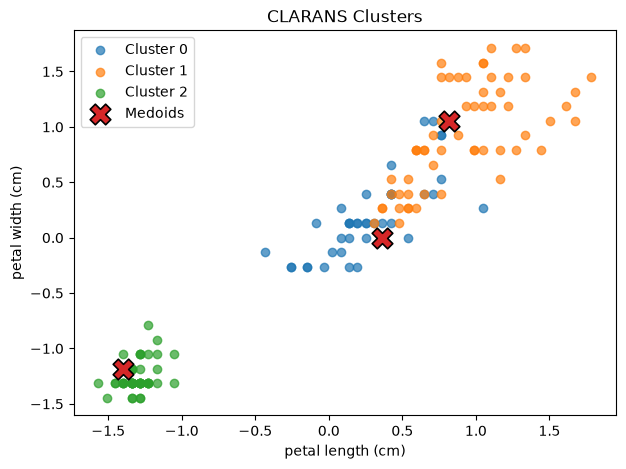

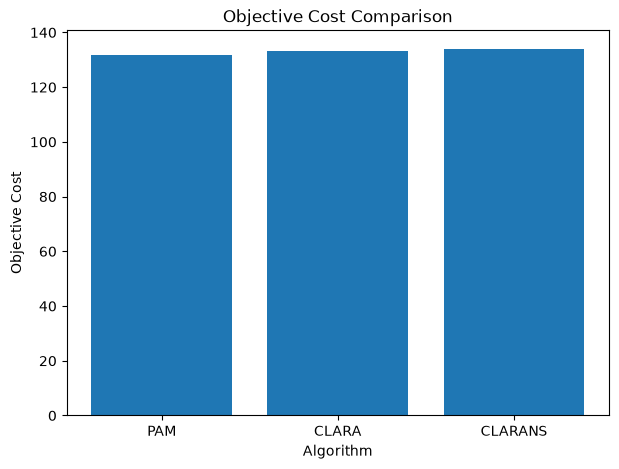

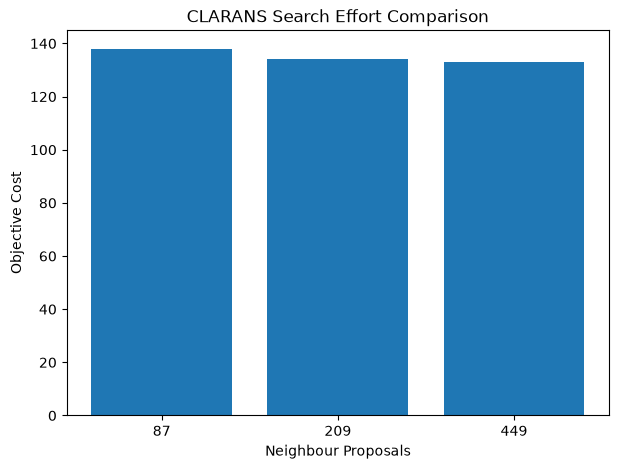

In [31]:
plot_clusters(X, pam_result, "PAM Clusters", feature_x=2, feature_y=3)
plot_clusters(X, clara_result, "CLARA Clusters", feature_x=2, feature_y=3)
plot_clusters(X, clarans_result, "CLARANS Clusters", feature_x=2, feature_y=3)

plt.figure(figsize=(7, 5))
plt.bar(comparison_df["Algorithm"], comparison_df["Objective Cost"])
plt.xlabel("Algorithm")
plt.ylabel("Objective Cost")
plt.title("Objective Cost Comparison")
plt.show()

plt.figure(figsize=(7, 5))
plt.bar(clarans_parameter_df["Neighbour Proposals"].astype(str),
        clarans_parameter_df["Objective Cost"])
plt.xlabel("Neighbour Proposals")
plt.ylabel("Objective Cost")
plt.title("CLARANS Search Effort Comparison")
plt.show()

**PAM clusters:** The three clusters are reasonably separated in petal feature space, although some overlap remains. The marked medoids represent actual observations within the clusters.

**CLARA clusters:** CLARA produces three balanced clusters of sizes 52, 49, and 49. Its sample-based search gives a slightly higher objective cost than PAM.

**CLARANS clusters:** CLARANS identifies three clusters of sizes 42, 59, and 49. Randomized search produces a reasonable partition, though its objective cost is slightly higher than PAM's.

**Objective cost comparison:** PAM achieves the lowest cost (131.796), followed by CLARA (133.264) and CLARANS (134.010). PAM performs best on the objective being minimized.

**CLARANS search effort:** Increasing the search budget from 87 to 449 neighbour proposals reduces the final cost from 137.977 to 133.118, at the expense of additional computation.

**k vs objective cost:** Objective cost decreases as k increases from 2 to 5 for all three algorithms because more medoids can reduce distances to the nearest medoid.

**k vs silhouette score:** The silhouette score is highest at k = 2 (approximately 0.582) and decreases as k increases. More clusters reduce within-cluster distances but may weaken separation between clusters.

**CLARA sample size vs objective cost:** Increasing sample size from 20 to 80 reduces full-data cost from 140.663 to 132.128. Larger samples appear to identify better representative medoids in these experiments.

**CLARA sample size vs runtime:** Runtime increases from approximately 0.45 seconds for sample size 20 to 9.51 seconds for sample size 80. Larger samples improve solution quality here but require substantially more computation.

**CLARANS search effort vs cost:** The final cost decreases as neighbour proposals increase across the tested settings. This demonstrates the trade-off between search effort and solution quality.

### Task 21: Complexity and Practical Observations

Pairwise distance calculations across all pairs require \(O(N^2)\) work if computed as a full matrix. A PAM iteration evaluates swaps between \(k\) medoids and \(N-k\) non-medoids; recomputing all point-to-medoid distances for every candidate is expensive as \(N\) grows.

- **PAM:** Advantage — direct local search over medoid swaps; limitation — costly on large datasets; suitable for small or medium datasets.
- **CLARA:** Advantage — performs medoid search on samples while evaluating candidates on the full dataset; limitation — samples may miss strong medoids; suitable for larger datasets.
- **CLARANS:** Advantage — randomized neighbourhood exploration avoids checking every possible swap; limitation — outcomes vary with random search and budgets; suitable when a tunable search-effort/quality trade-off is needed.

### Task 22: Final Results Table

In [33]:
final_rows = [
    {
        "Experiment": "PAM",
        "Setting": "k=3; max_iter=100",
        "Result": f"Medoids={pam_result['medoids'].tolist()}; cost={pam_result['cost']:.4f}; "
                  f"cluster sizes={np.bincount(pam_result['assignments'], minlength=3).tolist()}"
    },
    {
        "Experiment": "CLARA",
        "Setting": f"k=3; sample_size={CLARA_SAMPLE_SIZE}; samples={CLARA_NUM_SAMPLES}",
        "Result": f"Best sample={clara_result['best_sample']}; medoids={clara_result['medoids'].tolist()}; "
                  f"cost={clara_result['cost']:.4f}"
    },
    {
        "Experiment": "CLARANS",
        "Setting": f"k=3; num_local={CLARANS_NUM_LOCAL}; max_neighbors={CLARANS_MAX_NEIGHBORS}",
        "Result": f"Cost={clarans_result['cost']:.4f}; proposals={len(clarans_result['proposals'])}; "
                  f"accepted swaps={clarans_result['accepted_swaps']}"
    },
    {
        "Experiment": "Evaluation",
        "Setting": "Same standardized data; k=3",
        "Result": "Silhouette, ARI and NMI are reported in the evaluation table above."
    },
    {
        "Experiment": "k experiment",
        "Setting": "k=2, 3, 4, 5",
        "Result": "Objective cost, silhouette score and cluster sizes are reported in the k experiment table."
    },
    {
        "Experiment": "Parameter experiments",
        "Setting": "CLARA sample size; CLARANS search budget",
        "Result": "Cost and runtime trade-offs are reported in the corresponding tables."
    }
]

display(pd.DataFrame(final_rows))

,Experiment,Setting,Result
0,PAM,k=3; max_iter=100,"Medoids=[55, 7, 112]; cost=131.7958; cluster s..."
1,CLARA,k=3; sample_size=40; samples=5,"Best sample=2; medoids=[94, 0, 139]; cost=133...."
2,CLARANS,k=3; num_local=5; max_neighbors=20,Cost=134.0104; proposals=209; accepted swaps=29
3,Evaluation,Same standardized data; k=3,"Silhouette, ARI and NMI are reported in the ev..."
4,k experiment,"k=2, 3, 4, 5","Objective cost, silhouette score and cluster s..."
5,Parameter experiments,CLARA sample size; CLARANS search budget,Cost and runtime trade-offs are reported in th...


### Task 23: Observations and Conclusion

### Observations

1. PAM selects medoids at indices 55, 7, and 112, producing clusters of sizes 55, 50, and 45. The medoids represent observations with different petal measurements, helping distinguish groups in feature space.

2. PAM achieves the lowest objective cost (131.796), followed by CLARA (133.264) and CLARANS (134.010). PAM also obtains the highest ARI (0.642) and NMI (0.675), while CLARA achieves the highest silhouette score (0.459).

3. CLARA's best sample is sample 2, with a full-data cost of 133.264. Increasing sample size from 20 to 80 improves the cost from 140.663 to 132.128, but runtime increases substantially.

4. CLARANS improves its cost from 137.977 to 133.118 as the search budget increases across the tested settings. More neighbour proposals and restarts can improve the solution but increase computational effort.

5. Increasing k from 2 to 5 reduces objective cost but also reduces silhouette scores in these experiments. The highest silhouette score occurs at k = 2, showing that minimizing cost and maximizing cluster separation can favour different values of k.

6. Standardization ensures that all four features contribute comparably to Euclidean distance. Results still depend on initialization, sample selection, random seed, and search parameters.

### Comparison of Algorithms

PAM exhaustively evaluates possible medoid swaps and obtains the lowest cost, but it is computationally expensive. CLARA reduces search effort by running PAM on samples and evaluating candidate medoids on the full dataset. CLARANS explores a randomized neighbourhood, offering a tunable trade-off between computation and solution quality.

In this run, PAM takes approximately 4.70 seconds, CLARA 2.00 seconds, and CLARANS 0.68 seconds. These timings are implementation- and machine-dependent and should not be generalized from a single run.

### Conclusion

K-Medoids provides interpretable clusters through representative observations and can be useful for customer segmentation, robust grouping, and clustering with non-Euclidean dissimilarities. PAM is suitable for smaller datasets when solution quality is the priority, CLARA is useful for larger datasets, and CLARANS is appropriate when randomized search and configurable computational budgets are desirable. The choice of k, feature scaling, sample size, and search parameters should be guided by both objective cost and cluster-quality metrics.